#библиотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score as score
from sklearn.metrics import accuracy_score as accuracy
from sklearn.datasets import make_classification as mc
from sklearn.datasets import make_circles
from sklearn.datasets import make_blobs

from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.svm import SVR

from collections import defaultdict

import seaborn as sns

import time

from mlxtend.plotting import plot_decision_regions

# работа


1. Сгенерируйте линейно разделимый датасет для классификации из двух признаков. Постройте на нем опорно-векторный классификатор без ядра с параметром С=100. Изобразите границу принятия решения и линию зазора на графике.
 2. Сгенерируйте линейно неразделимый датасет с зазором между классами. Повторите виуальный анализ на нем.
    3. Сгенерируйте неразделимый датасет так, чтобы классы пересекались. Повторите построение и оценку метода опорных векторов на нем.

### 1. В первом задании поэкспериментируйте с различными значениями аргумента C класса SVC. Сделайте вывод о том, как он влияет на модель классификации.

In [ ]:
def PLOT(X,y,svm_linear):
  X0 = np.linspace(X[:, 0].min(),X[:, 0].max(), X.shape[0])

  plt.plot(X0,-svm_linear.intercept_[0]/svm_linear.coef_[0][1]-svm_linear.coef_[0][0]/svm_linear.coef_[0][1]*X0, c='k')

  plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
  plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)

  plt.title("Диаграмма рассеяния c границей принятия решения")
  plt.xlabel('X0')
  plt.ylabel('X1')
  plt.rcParams["figure.figsize"] = (4,4)
  plt.show()

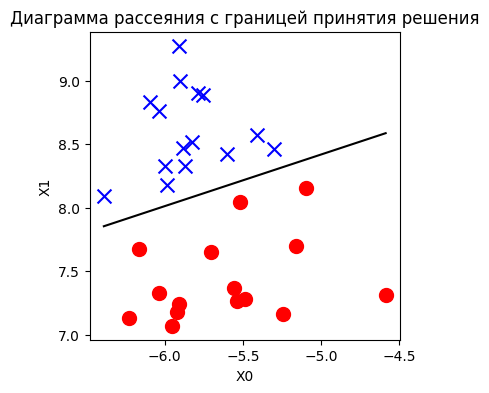

1.0
_____________


In [ ]:
def Compute(C = 100):
  x, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=0.4)
  m = SVC(kernel='linear', C=C)
  m.fit(x,y)
  PLOT(x,y,m)
  print(m.score(x,y))
  print('_____________')
Compute()

In [ ]:
for i in np.linspace(0.1,10,100):
  print(i)
  Compute(i)

Output hidden; open in https://colab.research.google.com to view.

### 2. В первом задании подвигайте точку нового предсказания. Убедитесь, что с другой стороны границы предсказывается другой класс. Как изменяется предсказание, если точка ляжет внутрь полосы зазора?

In [ ]:
def PLOT(X,svm_linear):
  y = svm_linear.predict(X)
  X0 = np.linspace(X[:, 0].min(),X[:, 0].max(), X.shape[0])

  plt.plot(X0,-svm_linear.intercept_[0]/svm_linear.coef_[0][1]-svm_linear.coef_[0][0]/svm_linear.coef_[0][1]*X0, c='k')

  plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
  plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)

  plt.title("Диаграмма рассеяния c границей принятия решения")
  plt.xlabel('X0')
  plt.ylabel('X1')
  plt.rcParams["figure.figsize"] = (4,4)
  plt.show()

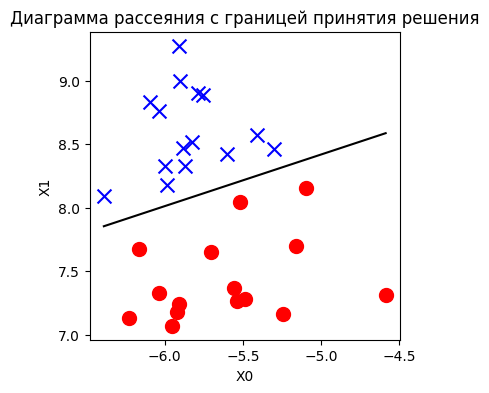

1.0


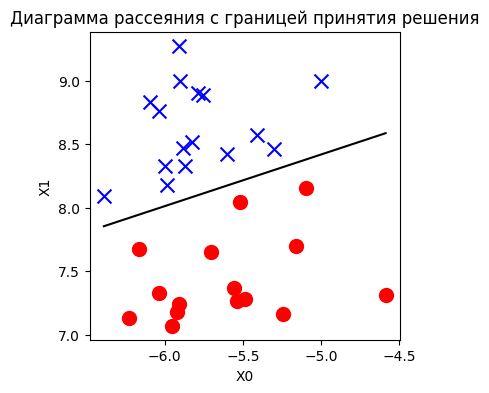

1.0


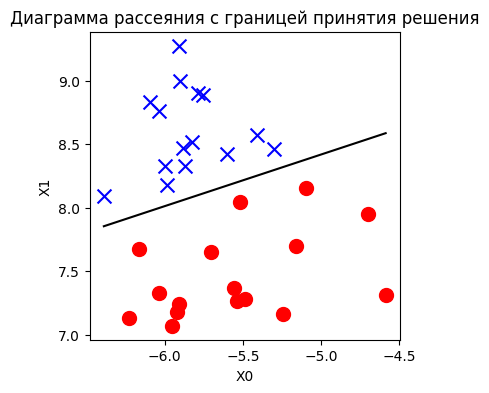

0.967741935483871


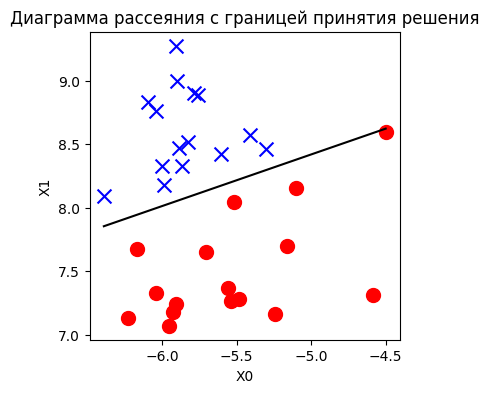

0.967741935483871


In [ ]:
#1
x, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=0.4)
m = SVC(kernel='linear', C=100)
m.fit(x,y)
PLOT(x,m)
print(m.score(x,y))

#2
x, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=0.4)
x = np.concatenate([x,np.array([[-5.0,9.0]])])
y = np.concatenate([y,[1]])
PLOT(x,m)
print(m.score(x,y))

#3
x, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=0.4)
x = np.concatenate([x,np.array([[-4.7,7.95]])])
y = np.concatenate([y,[1]])
PLOT(x,m)
print(m.score(x,y))

#4
x, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=0.4)
x = np.concatenate([x,np.array([[-4.5,8.595]])])
y = np.concatenate([y,[1]])
PLOT(x,m)
print(m.score(x,y))

не изменится, т.к. определяющим фактором является прямая принятия решений, а не полоса зазора

НО полоса зазора это место, где классы определяются плохо

### 3. Во втором задании повторите анализ с методом опорных векторов с другими видами ядер. Сравните вид границы принятия решения и показатели точности модели.

1.0


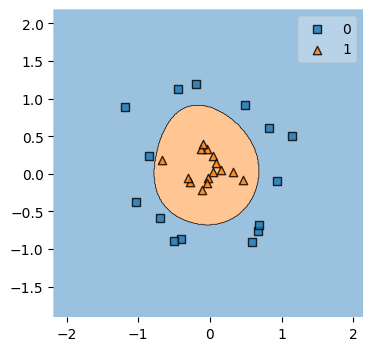

0.7


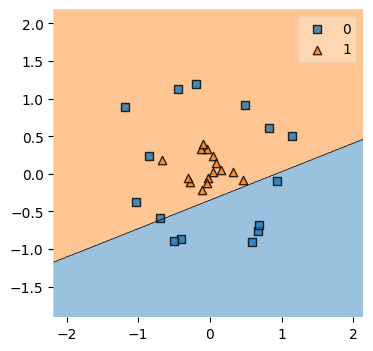

0.7


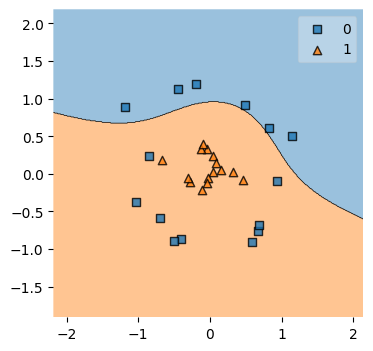

0.5


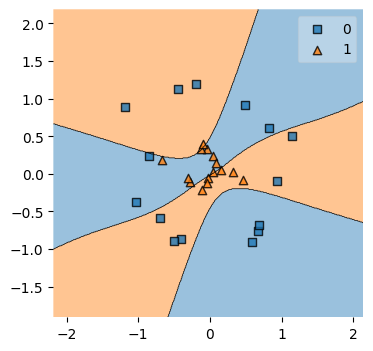

In [ ]:
def Compute(kernel):
  X, y = make_circles(n_samples=30, random_state=5, factor=.1, noise=.2)
  svm_rbf = SVC(kernel=kernel, C=100).fit(X, y)
  print(svm_rbf.score(X,y))
  plot_decision_regions(X, y, svm_rbf)
  plt.show()
Compute('rbf')
Compute('linear')
Compute('poly')
Compute('sigmoid')

### 4. В третьем задании поэкспериментируйте со значением аргумента C. Сделайтевывод о том, как он влияет на модель.

1.0
0.8666666666666667


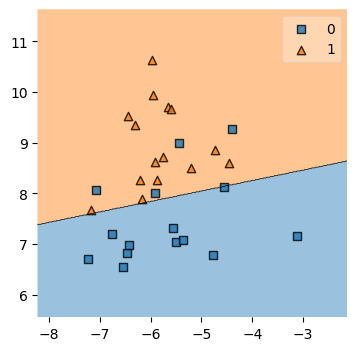

0.8889
0.8666666666666667


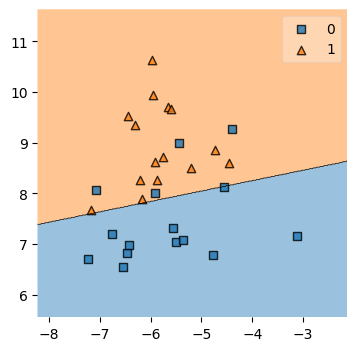

0.7778
0.8666666666666667


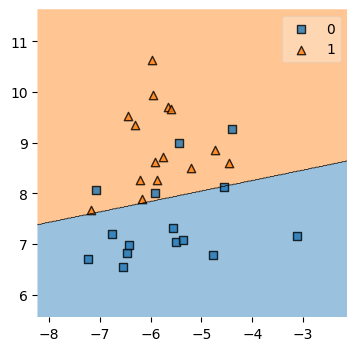

0.6667
0.8333333333333334


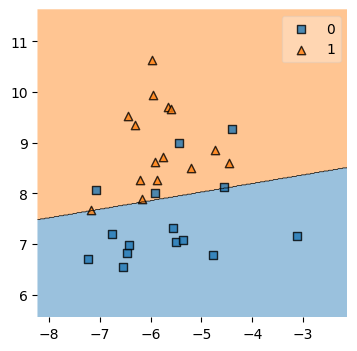

0.5556
0.8


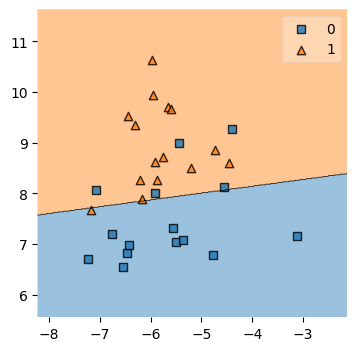

0.4445
0.8


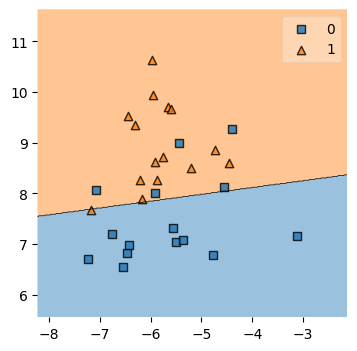

0.3333999999999999
0.8


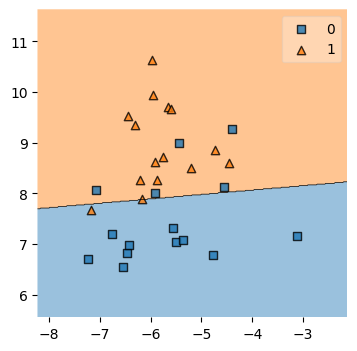

0.22229999999999994
0.8333333333333334


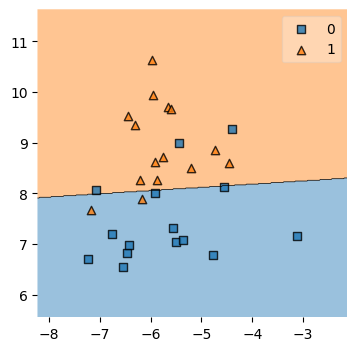

0.11119999999999997
0.8666666666666667


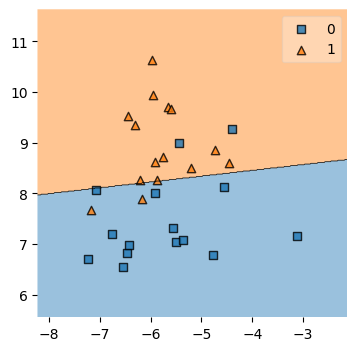

0.0001
0.7


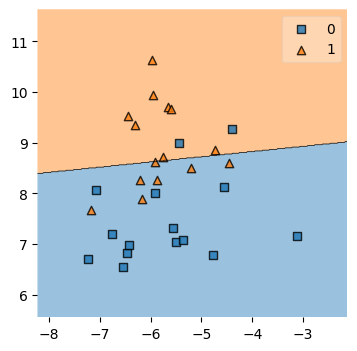

In [ ]:
def Compute(kernel,C):
  X, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=1)
  svm_rbf = SVC(kernel=kernel, C=C).fit(X, y)
  print(svm_rbf.score(X,y))
  plot_decision_regions(X, y, svm_rbf)
  plt.show()
for i in np.linspace(1,0.0001,10):
  print(i)
  Compute('linear',i)


### 5. В третьем задании примените классификатор без ядра. Познакомьтесь и примените класс Linear_SVC.

0.8333333333333334

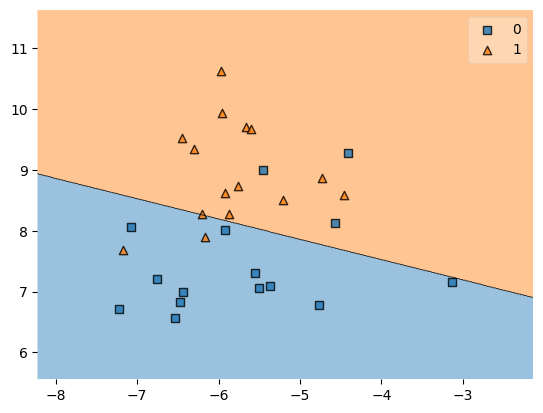

In [ ]:

x, y = make_blobs(n_features=2, n_samples=30, centers=2, random_state=5, cluster_std=1)
m = LinearSVC().fit(x,y)
plot_decision_regions(x, y, m)
plt.plot()
m.score(x,y)

### 6. Сгенерируйте датасет для классификации из 1000 точек и 5 атрибутов. Попробуйте применить метод опорных векторов на нем. Найдите методом подбора наилучшее ядро и значение С.

In [ ]:
x, y = mc(n_features=5, n_samples=1000, random_state=5)
m = SVC(kernel='linear', C=0.001).fit(x, y)
print(m.score(x,y))

0.882


In [ ]:
l = ['rbf','linear','poly','sigmoid']
C = [i for i in np.linspace(0.001,1000,100)]
def Compute(kernel,C):
  X, y = mc(n_features=5, n_samples=1000, random_state=5)
  svm_rbf = SVC(kernel=kernel, C=C).fit(X, y)
  return svm_rbf.score(X,y)

super=[]
for i in l:
  k=[]
  print(i)
  for j in C:
    k.append((Compute(i,j),i,j))
  print(k)
  super.append(sorted(k)[-1])
print('\n\n')
print(super)

rbf
[(0.501, 'rbf', 0.001), (0.932, 'rbf', 10.102), (0.937, 'rbf', 20.203000000000003), (0.937, 'rbf', 30.304000000000006), (0.938, 'rbf', 40.405), (0.938, 'rbf', 50.506), (0.939, 'rbf', 60.607000000000006), (0.939, 'rbf', 70.70800000000001), (0.937, 'rbf', 80.80900000000001), (0.938, 'rbf', 90.91000000000001), (0.94, 'rbf', 101.01100000000001), (0.941, 'rbf', 111.11200000000001), (0.943, 'rbf', 121.21300000000002), (0.943, 'rbf', 131.31400000000002), (0.942, 'rbf', 141.41500000000002), (0.942, 'rbf', 151.51600000000002), (0.942, 'rbf', 161.61700000000002), (0.942, 'rbf', 171.71800000000002), (0.942, 'rbf', 181.81900000000002), (0.941, 'rbf', 191.92000000000002), (0.943, 'rbf', 202.02100000000002), (0.943, 'rbf', 212.122), (0.943, 'rbf', 222.223), (0.943, 'rbf', 232.324), (0.943, 'rbf', 242.42500000000004), (0.943, 'rbf', 252.52600000000004), (0.943, 'rbf', 262.627), (0.943, 'rbf', 272.728), (0.943, 'rbf', 282.829), (0.943, 'rbf', 292.93), (0.943, 'rbf', 303.031), (0.943, 'rbf', 313.13

наилучшим ядром для данной задачи оказалось rbf со значением C = 787.879

### 7. Попробуйте данную модель с большим количеством точек. На каком количестве обучение начинает занимать существенное время?

In [2]:
def Compute(samples,kernel='rbf',C=5):
  X, y = mc(n_features=5, n_samples=samples, random_state=5,class_sep=0.8)
  t1 = time.time()
  svm_rbf = SVC(kernel=kernel, C=C).fit(X, y)
  t2 = time.time()
  return (svm_rbf.score(X,y),t2-t1)

for i in range(10,100000,1000):
  scor,tim = Compute(i)
  print(f'Score for {i} samples is {scor}\ntime elapsed:{tim}\n')

Score for 10 samples is 1.0
time elapsed:0.006021738052368164

Score for 1010 samples is 0.9732673267326732
time elapsed:0.0468142032623291

Score for 2010 samples is 0.9019900497512437
time elapsed:0.20462846755981445

Score for 3010 samples is 0.891029900332226
time elapsed:0.3550400733947754

Score for 4010 samples is 0.8845386533665835
time elapsed:0.5973162651062012

Score for 5010 samples is 0.8459081836327346
time elapsed:1.74141263961792

Score for 6010 samples is 0.9597337770382696
time elapsed:0.8395318984985352

Score for 7010 samples is 0.9405135520684736
time elapsed:1.8714661598205566

Score for 8010 samples is 0.9086142322097378
time elapsed:3.0556814670562744

Score for 9010 samples is 0.8710321864594894
time elapsed:3.397594451904297

Score for 10010 samples is 0.9652347652347653
time elapsed:0.9054582118988037

Score for 11010 samples is 0.8902815622161672
time elapsed:4.03720498085022

Score for 12010 samples is 0.8542048293089093
time elapsed:5.618626117706299

Scor

KeyboardInterrupt: 

In [ ]:
t1 = time.time()
time.sleep(5)
t2 = time.time()
t2-t1

5.00649356842041

### 8. Примените метод опорных векторов для задачи множественной классификации. Самостоятельно сгенерируйте визуализируемый датасет для этой задачи. Поробуйте изобразить границу принятия решений и зазор.

In [ ]:
x, y = mc(n_features=3,n_classes=3, n_informative=3,n_redundant=0, n_samples=1000, random_state=5)
m = SVC(kernel='rbf', C=1000,decision_function_shape="ovr").fit(x, y)
print(m.score(x,y))
df=pd.concat([pd.DataFrame(x),pd.Series(y,name='y')],axis=1)


0.943


In [ ]:
pd.Series(y).unique()

array([1, 0, 2])

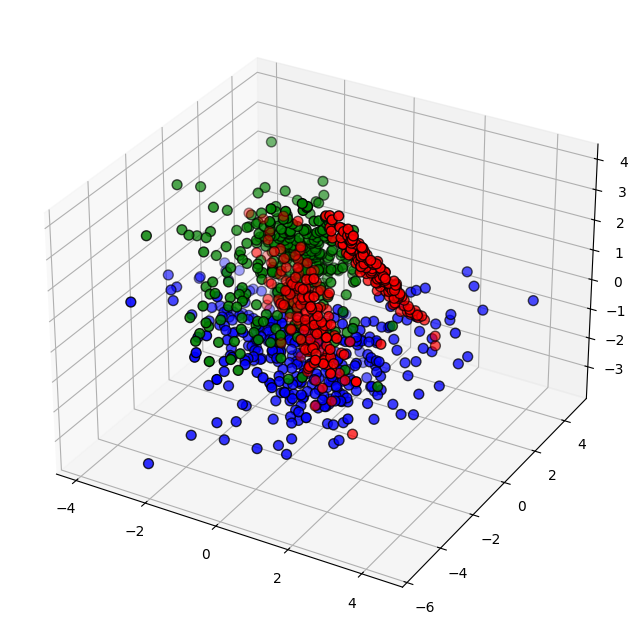

In [ ]:
xr = np.linspace(x[:, 0].min() - 1, x[:, 0].max() + 1, 30)
yr = np.linspace(x[:, 1].min() - 1, x[:, 1].max() + 1, 30)
zf = x[:, 2].mean()

xx, yy = np.meshgrid(xr, yr)
grid = np.c_[xx.ravel(), yy.ravel(), np.full_like(xx.ravel(), zf)]
preds = m.predict(grid).reshape(xx.shape)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

uc = np.unique(y)
colors = ["red", "blue", "green"]
for idx, ci in enumerate(uc):
    ax.scatter(x[y == ci, 0], x[y == ci, 1], x[y == ci, 2], label=f"Class {ci}", color=colors[idx], edgecolor="k", s=50)

plt.show()

### 9. Выберите из библиотеки sklearn готовый датасет для классификации и попробуйте смоделировать его при помощи метода опорных векторов.

In [ ]:
from sklearn.datasets import load_iris
p = load_iris(as_frame=True).frame
x = p.drop('target',axis=1)
y = p[['target']]
m = SVC(kernel='linear',decision_function_shape="ovr").fit(x,y)
m.score(x,y)

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


0.9933333333333333

In [ ]:
from sklearn.datasets import load_iris
p = load_iris(as_frame=True).frame
x = p.drop('target',axis=1)
y = p[['target']]

Ntest = np.int64(np.ceil(p.shape[0] * 0.2))

xl,yl=x.iloc[Ntest:,:],y.iloc[Ntest:]
xt,yt=x.iloc[:Ntest,:],y.iloc[:Ntest]

m = SVC(kernel='linear',decision_function_shape="ovr").fit(xl,yl)
m.score(xt,yt)

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


1.0

### 10. Повторите такой же анализ для задачи регрессии и соответствующего датасета.

In [ ]:
from sklearn.datasets import load_diabetes
p = load_diabetes(as_frame=True).frame
x = p.drop('target',axis=1)
y = p['target']
m = SVR(kernel='rbf',C=10000).fit(x,y.values)
m.score(x,y)

0.9587859010630253

In [ ]:
p = load_diabetes(as_frame=True).frame
x = p.drop('target',axis=1)
y = p['target']

Ntest = np.int64(np.ceil(p.shape[0] * 0.2))

xl,yl=x.iloc[Ntest:,:],y.iloc[Ntest:]
xt,yt=x.iloc[:Ntest,:],y.iloc[:Ntest]

m = SVR(kernel='rbf',C=0.8189219448928).fit(xl,yl.values)
m.score(xt,yt)

0.12365707690477346

In [ ]:
p = load_diabetes(as_frame=True).frame
x = p.drop('target',axis=1)
y = p['target']

Ntest = np.int64(np.ceil(p.shape[0] * 0.2))

xl,yl=x.iloc[Ntest:,:],y.iloc[Ntest:]
xt,yt=x.iloc[:Ntest,:],y.iloc[:Ntest]


l = ['rbf','linear','poly','sigmoid']
C = [i for i in np.linspace(0.001,1000,100)]
def Compute(kernel,C):
  svm_rbf = SVR(kernel=kernel, C=C).fit(xl, yl)
  return svm_rbf.score(xt,yt)

super=[]
for i in l:
  k=[]
  print(i)
  for j in C:
    k.append((Compute(i,j),i,j))
  super.append(sorted(k)[-1])
print('\n\n')
print(super)

rbf
linear
poly
sigmoid



[(0.36850407172721134, 'rbf', 20.203000000000003), (0.4351507280165178, 'linear', 545.455), (0.41731298181768517, 'poly', 50.506), (0.4146578237914308, 'sigmoid', 10.102)]


In [ ]:
p = load_diabetes(as_frame=True).frame
x = p.drop('target',axis=1)
y = p['target']

Ntest = np.int64(np.ceil(p.shape[0] * 0.2))

xl,yl=x.iloc[Ntest:,:],y.iloc[Ntest:]
xt,yt=x.iloc[:Ntest,:],y.iloc[:Ntest]


l = ['rbf','linear','poly','sigmoid']
C = [i for i in np.linspace(1000,100000,100)]
def Compute(kernel,C):
  svm_rbf = SVR(kernel=kernel, C=C).fit(xl, yl)
  return svm_rbf.score(xt,yt)

super=[]
for i in l:
  k=[]
  print(i)
  for j in C:
    k.append((Compute(i,j),i,j))
  super.append(sorted(k)[-1])
print('\n\n')
print(super)

rbf
linear
poly
sigmoid



[(0.13583931954110684, 'rbf', 1000.0), (0.45521771769182184, 'linear', 42000.0), (-0.7753050864615647, 'poly', 1000.0), (-4416.679692193479, 'sigmoid', 1000.0)]
